In [1]:
# Required imports and XOR Dataset:
import numpy as np
import matplotlib.pyplot as plt
import copy

np.random.seed(42)

np.set_printoptions(precision=4, suppress=True)

X_xor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_xor = np.array([0., 1., 1., 0.])

print("XOR Input:")
print(X_xor)

print("\nXOR Target:")
print(y_xor)

XOR Input:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

XOR Target:
[0. 1. 1. 0.]


In [2]:
# Activation Functions:
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def leaky_relu(x, alpha=0.01):
    return np.where(x > 0, x, alpha * x)

def binary_cross_entropy(y, predictions):
    y = y.reshape(-1, 1)
    predictions = np.clip(predictions, 1e-8, 1 - 1e-8)

    return -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))


def accuracy(y, predictions):
    predicted_labels = (predictions.ravel() >= 0.5).astype(int)
    return np.mean(predicted_labels == y.astype(int))

def initialize_network(hidden_width=4, seed=42):
    rng = np.random.default_rng(seed)

    return{
        "W1": rng.normal(0, np.sqrt(2 / 2), (2, hidden_width)),
        "b1": np.zeros((1, hidden_width)),
        "W2": rng.normal(0, np.sqrt(1 / hidden_width), (hidden_width, 1)),
        "b2": np.zeros((1, 1))
    }

In [3]:
def forward_pass(X, params, activation="relu"):
    W1 = params["W1"]
    b1 = params["b1"]

    W2 = params["W2"]
    b2 = params["b2"]

    z1 = X @ W1 + b1

    if activation == "relu":
        a1 = relu(z1)
    elif activation == "leaky_relu":
        a1 = leaky_relu(z1)
    elif activation == "sigmoid":
        a1 = sigmoid(z1)
    else:
        raise valueError("Unknown Activation")

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    cache = {
        "X": X, "z1": z1, "a1": a1, "z2": z2, "a2": a2
    }

    return a2, cache


def calculate_loss(X, y, params, activation="relu"):
    predictions, _ = forward_pass(X, params, activation)

    return binary_cross_entropy(y, predictions)

# **Part A — Understand what a gradient is**
## **TASK 01 — Measure gradients by nudging**

* Neural networks consist of weights and biases. During training, we need to determine how much each weight and bias should be adjusted to minimize the loss.

* The direction and magnitude of this adjustment are referred to as the gradient.

* A simple approach to calculating a numerical gradient:
1. Take the original value of a weight.
2. Add a small value $h$ to that weight.
3. Calculate the loss.
4. Subtract $h$ from the original weight.
5. Calculate the loss again.
6. Estimate the gradient using the difference between the two loss values.



**Formula :**
dL/dw ≈ L(w + h) - L(w - h) / 2h

Where L = loss, w = Weight, h = small step size

In [4]:
def numerical_gradients(X, y, params, h=1e-5, activation="relu"):
    gradients = {}

    for key in params:
        gradients[key] = np.zeros_like(params[key])

        for index in np.ndindex(params[key].shape):
            original_value = params[key][index]

            # Add small value
            params[key][index] = original_value + h
            loss_plus = calculate_loss(X, y, params, activation)

            # substract small value
            params[key][index] = original_value - h
            loss_minus = calculate_loss(X, y, params, activation)

            # restore original value
            params[key][index] = original_value

            # central difference formula
            gradients[key][index] = (loss_plus - loss_minus) / (2 * h)

    return gradients

In [5]:
# Small random networks
params = initialize_network(hidden_width=4, seed=42)
loss_before = calculate_loss(X_xor, y_xor, params)

grads = numerical_gradients(X_xor, y_xor, params, h=1e-5)
loss_after = calculate_loss(X_xor, y_xor, params)

print("Loss Before:", loss_before.round(4))
print("Loss After:", loss_after.round(4))

print("\nGradient Shape:")
for key in grads:
    print(key, grads[key].shape)

print("\nNumeric Gradients:")
for key in grads:
    print(key)
    print(grads[key])


assert np.isclose(loss_before, loss_after), "Parameters were not restored!"

Loss Before: 0.7051
Loss After: 0.7051

Gradient Shape:
W1 (2, 4)
b1 (1, 4)
W2 (4, 1)
b2 (1, 1)

Numeric Gradients:
W1
[[0.0007 0.     0.0351 0.031 ]
 [0.     0.     0.0183 0.0634]]
b1
[[ 0.0002 -0.0267  0.0091  0.0553]]
W2
[[-0.0254]
 [ 0.    ]
 [ 0.0652]
 [ 0.0234]]
b2
[[0.0832]]


**Conclusion :-**
* Numerical gradients estimate the effect of changing each weight and bias on the network loss.
* Central difference calculates gradients using both positive and negative perturbations.
* The original parameters must be restored after every calculation.
* A very large step size can reduce approximation accuracy, while an extremely small step size can increase floating-point rounding errors.
* Numerical gradients are useful for checking analytical backpropagation, but they are computationally expensive.

* Numerical gradients were successfully calculated using the central difference method.
* The original loss and restored loss were both 0.7051, confirming that all parameters were correctly restored after gradient calculations.
* The gradient shapes matched the corresponding parameter shapes:  
W1: (2, 4)  
b1: (1, 4)  
W2: (4, 1)  
b2: (1, 1)  

## **TASK 02 — Train with brute force, and price it**

In [6]:
# Initialize parameters
import time

def train_numerical(hidden_width, seed=42, lr=0.01, max_epochs=3000):
    params = initialize_network(hidden_width, seed)
    parameter_count = sum(value.size for value in params.values())

    forward_pass_count = 0
    losses = []

    start_time = time.time()

    for epoch in range(max_epochs):
        gradients = numerical_gradients(X_xor, y_xor, params)

        forward_pass_count += 2 * parameter_count

        for key in params:
            params[key] -= lr * gradients[key]

        predictions, _ = forward_pass(X_xor, params)
        forward_pass_count += 1

        loss = binary_cross_entropy(y_xor, predictions)
        losses.append(loss)

        if accuracy(y_xor, predictions) == 1.0:
            break

    elapsed_time = time.time() - start_time

    predictions, _ = forward_pass(X_xor, params)
    forward_pass_count += 1

    return {
        "params": params,
        "accuracy": accuracy(y_xor, predictions),
        "loss": losses[-1],
        "epochs": epoch + 1,
        "time": elapsed_time,
        "forward_passes": forward_pass_count,
        "parameter_count": parameter_count
    }

In [7]:
numerical_results = []
for width in [4, 8, 16, 32]:
    result = train_numerical(hidden_width=width, seed=42)
    numerical_results.append(result)

    print("\nHidden Neurons:", width)
    print("Parameters:", result["parameter_count"])
    print("Accuracy:", result["accuracy"])
    print("Epochs:", result["epochs"])
    print("Forward Passes:", result["forward_passes"])
    print("Time:", result["time"], "Seconds")


Hidden Neurons: 4
Parameters: 17
Accuracy: 1.0
Epochs: 2666
Forward Passes: 93311
Time: 1.3988676071166992 Seconds

Hidden Neurons: 8
Parameters: 33
Accuracy: 1.0
Epochs: 1845
Forward Passes: 123616
Time: 1.741161823272705 Seconds

Hidden Neurons: 16
Parameters: 65
Accuracy: 1.0
Epochs: 1050
Forward Passes: 137551
Time: 1.8727662563323975 Seconds

Hidden Neurons: 32
Parameters: 129
Accuracy: 1.0
Epochs: 212
Forward Passes: 54909
Time: 0.7490746974945068 Seconds


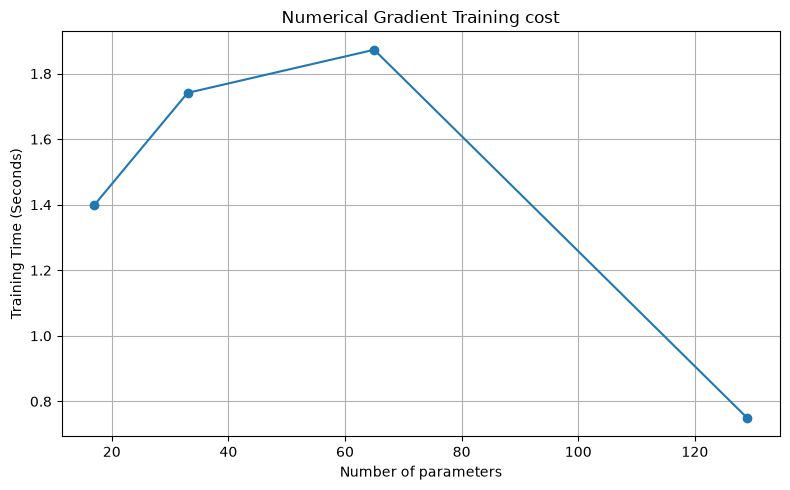

In [8]:
# Plot time against parameter count.
parameter_counts = [result["parameter_count"] for result in numerical_results]

training_times = [result["time"] for result in numerical_results]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(parameter_counts, training_times, marker="o")

ax.set_xlabel("Number of parameters")
ax.set_ylabel("Training Time (Seconds)")
ax.set_title("Numerical Gradient Training cost")
ax.grid(True)

plt.tight_layout()
plt.show()

# **Part B — Derive it**
## **TASK 03 — The chain rule on a tiny graph**

In [9]:
def tiny_network_squared_gradient(w, x, y):
    z = w * x
    a = sigmoid(z)

    dL_da = 2 * (a - y)
    da_dz = a * (1 - a)
    dz_dw = x

    gradient = dL_da * da_dz * dz_dw

    return gradient

In [10]:
def tiny_network_squared_loss(w, x, y):
    a = sigmoid(w * x)

    return (a - y) ** 2


w = 0.7
x = 1.5
y = 1.0

analytic_gradient = tiny_network_squared_gradient(w, x, y)
h = 1e-5

numerical_gradient = (tiny_network_squared_loss(w + h, x, y) - tiny_network_squared_loss(w - h, x, y)) / (2 * h)

print(f"Analytical: {analytic_gradient:.10f}")
print(f"Numerical: {numerical_gradient:.10f}")
print("Difference", abs(analytic_gradient - numerical_gradient))

Analytical: -0.1493350036
Numerical: -0.1493350036
Difference 6.262490526154352e-12


In [11]:
# Cross-entropy loss
def tiny_network_bce_loss(w, x, y):
    a = sigmoid(w * x)
    a = np.clip(a, 1e-8, 1 - 1e-8)

    return -(y * np.log(a) + (1 - y) * np.log(1 - a))

In [12]:
def tiny_network_bce_gradient(w, x, y):
    a = sigmoid(w * x)

    return (a - y) * x


analytic_bce = tiny_network_bce_gradient(w, x, y)

numeric_bce = (tiny_network_bce_loss(w + h, x, y) - tiny_network_bce_loss(w - h, x, y)) / (2 * h)


print(f"Analytical BCE: {analytic_bce:.10f}")
print(f"Numerical BCE: {numeric_bce:.10f}")
print("Difference", abs(analytic_bce - numeric_bce))

Analytical BCE: -0.3888376512
Numerical BCE: -0.3888376512
Difference 6.106948280404367e-12


* In the derivative of BCE, the \(a(1-a)\) factor from the sigmoid function cancels out. Consequently, the BCE gradient remains useful even when the prediction is confidently wrong. In contrast, with squared error, the small derivative of the sigmoid function can cause the gradient to become extremely small.

## **TASK 04 — The full backward pass**

In [13]:
def backward_pass(y, params, cache, activation="relu"):
    X = cache["X"]
    z1 = cache["z1"]
    a1 = cache["a1"]
    a2 = cache["a2"]

    m = X.shape[0]
    y = y.reshape(-1, 1)

    # output error
    dz2 = (a2 - y) / m
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # pass error backward
    da1 = dz2 @ params["W2"].T

    if activation == "relu":
        dz1 = da1 * (z1 > 0)
    elif activation == "leaky_relu":
        dz1 = da1 * np.where(z1 > 0, 1, 0.01)
    elif activation == "sigmoid":
        hidden_activation = sigmoid(z1)
        dz1 = da1 * hidden_activation * (1 - hidden_activation)

    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2
    }

In [14]:
# Gradient Checking
def gradient_check(X, y, params, activation="relu"):
    predictions, cache = forward_pass(X, params, activation)
    analytic = backward_pass(y, params, cache, activation)
    numeric = numerical_gradients(X, y, params, h=1e-5, activation=activation)

    print("Gradient check results:")

    errors = {}

    for key in analytic:
        numerator = np.linalg.norm(analytic[key] - numeric[key])
        denominator = (np.linalg.norm(analytic[key])
                    + np.linalg.norm(numeric[key])
                    + 1e-12)

        relative_error = numerator / denominator
        errors[key] = relative_error

        print(key, "Relative error:", relative_error)

    return errors


params = initialize_network(4, seed=42)

errors = gradient_check(X_xor, y_xor, params)

Gradient check results:
W1 Relative error: 4.342634052399374e-11
b1 Relative error: 0.46222437094982455
W2 Relative error: 3.779126357524247e-11
b2 Relative error: 3.6711577631073965e-11


In [15]:
# Deliberately introduce a bug
predictions, cache = forward_pass(X_xor, params)
correct_gradients = backward_pass(y_xor, params, cache)

broken_gradients = {
    key: value.copy()
    for key, value in correct_gradients.items()
}

# Deliberately break one gradient
broken_gradients["W2"] = -broken_gradients["W2"]

print("Correct W2 Gradient:")
print(correct_gradients["W2"])

print("\nBroken W2 Gradient:")
print(broken_gradients["W2"])

Correct W2 Gradient:
[[-0.0254]
 [ 0.    ]
 [ 0.0652]
 [ 0.0234]]

Broken W2 Gradient:
[[ 0.0254]
 [-0.    ]
 [-0.0652]
 [-0.0234]]


In [16]:
numerical = numerical_gradients(X_xor, y_xor, params)
difference = np.linalg.norm(broken_gradients["W2"] - numerical["W2"])
denominator = (np.linalg.norm(broken_gradients["W2"])
              + np.linalg.norm(numerical["W2"])
              + 1e-12)


print("Broken W2 relative error:", difference / denominator)

Broken W2 relative error: 0.99999999999322


# **Part C — Train, and discover what training cannot do**
## **TASK 05 — XOR, learned not typed**

In [17]:
def train_analytic(hidden_width=4, seed=42, lr=0.1, epochs=10000, activation="relu"):
    params = initialize_network(hidden_width, seed)
    losses = []

    start_time = time.time()

    for epoch in range(epochs):
        predictions, cache = forward_pass(X_xor, params, activation)
        loss = binary_cross_entropy(y_xor, predictions)
        losses.append(loss)

        gradients = backward_pass(y_xor, params, cache, activation)

        for key in params:
            params[key] -= lr * gradients[key]

        predictions, _ = forward_pass(X_xor, params, activation)

        if accuracy(y_xor, predictions) == 1.0:
            break

    elapsed = time.time() - start_time

    predictions, _ = forward_pass(X_xor, params, activation)

    return {
        "params": params,
        "losses": losses,
        "accuracy": accuracy(y_xor, predictions),
        "time": elapsed,
        "epochs": epoch + 1,
        "predictions": predictions
    }

In [18]:
result = train_analytic(hidden_width=4, seed=42, lr=0.1)

print("Accuracy:", result["accuracy"])
print("Epochs:", result["epochs"])
print("Time:", result["time"])

print("\nPredictions:")
print(result["predictions"])

print("\nLearned weights:")
for key, value in result["params"].items():
    print(key)
    print(value)

Accuracy: 1.0
Epochs: 490
Time: 0.03854942321777344

Predictions:
[[0.2768]
 [0.5021]
 [0.9294]
 [0.1235]]

Learned weights:
W1
[[ 1.245  -1.04    1.333   1.7594]
 [-1.951  -1.3022 -0.6644 -1.7698]]
b1
[[-0.0013  0.      0.648  -0.0159]]
W2
[[ 1.206 ]
 [-0.4265]
 [-1.4948]
 [ 2.3119]]
b2
[[0.0082]]


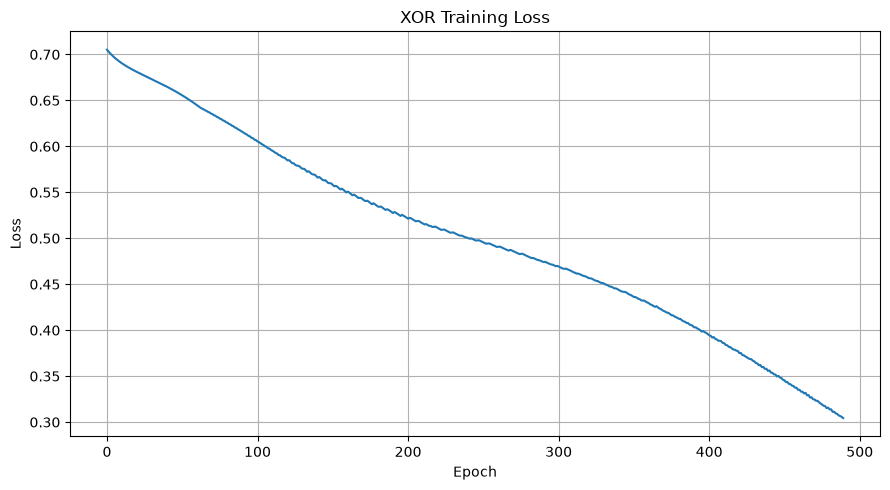

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(result["losses"])

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("XOR Training Loss")
ax.grid(True)

plt.tight_layout()
plt.show()

In [20]:
# Compare numerical and analytical training time
analytic_time = result["time"]

print("Numerical Training Time:", numerical_results[0]["time"], "seconds")

print("Analytical Training Time:", analytic_time, "seconds")

if analytic_time > 0:
    print("Numerical / Analytical time ratio:", numerical_results[0]["time"] / analytic_time)

Numerical Training Time: 1.3988676071166992 seconds
Analytical Training Time: 0.03854942321777344 seconds
Numerical / Analytical time ratio: 36.28764039384494


In [21]:
# Train with five different seeds
seed_results = []

for seed in [1, 2, 3, 4, 5]:
    r = train_analytic(hidden_width=4, seed=seed, lr=0.1)
    seed_results.append(r)

    print("\nSeed:", seed)
    print("Accuracy:", r["accuracy"])
    print("Predictions:", r["predictions"].ravel())

    for key in r["params"]:
        print(key)
        print(r["params"][key])


Seed: 1
Accuracy: 1.0
Predictions: [0.4701 0.59   0.5008 0.4994]
W1
[[ 0.3379  0.8156  0.3782 -1.3032]
 [ 0.891   0.4351 -0.537   0.7548]]
b1
[[0.0002 0.0001 0.0021 0.0028]]
W2
[[0.0511]
 [0.0453]
 [0.1862]
 [0.5548]]
b2
[[-0.1217]]

Seed: 2
Accuracy: 1.0
Predictions: [0.3676 0.9337 0.5001 0.0922]
W1
[[-0.4773 -0.5497 -0.4131 -2.4415]
 [ 2.0418  1.1055 -0.3254  2.393 ]]
b1
[[ 0.4668 -0.032   0.     -0.0083]]
W2
[[-1.163 ]
 [ 0.1426]
 [ 0.4888]
 [ 2.2685]]
b2
[[0.0003]]

Seed: 3
Accuracy: 1.0
Predictions: [0.3808 0.5008 0.9085 0.1033]
W1
[[ 2.1679 -2.5557  2.1782 -0.5678]
 [-0.4916 -0.2156 -2.1843 -0.2319]]
b1
[[ 0.4897  0.     -0.0206  0.    ]]
W2
[[-0.9995]
 [ 1.6615]
 [ 2.2936]
 [-0.1763]]
b2
[[0.0033]]

Seed: 4
Accuracy: 1.0
Predictions: [0.336  0.5018 0.9397 0.3387]
W1
[[-0.6518 -0.1747  1.8295 -0.661 ]
 [-1.6414 -0.0052 -1.8497  0.6728]]
b1
[[ 0.      0.     -0.0197  0.0089]]
W2
[[-0.8041]
 [ 0.1209]
 [ 1.8987]
 [ 1.0229]]
b2
[[-0.6901]]

Seed: 5
Accuracy: 0.75
Predictions: [0.33

## **TASK 06 — Existence against findability**

In [22]:
widths = [2, 3, 4, 8, 16, 32]
seeds = range(20)

success_table = []
failed_two_neuron_runs = []

for width in widths:
    success = 0
    failed_runs = []

    for seed in seeds:
        r = train_analytic(hidden_width=width, seed=seed, lr=0.1, epochs=5000)
        if r["accuracy"] == 1.0:
            success += 1

        else:
            if width == 2:
                failed_runs.append({
                    "seed": seed,
                    "loss": r["losses"][-1],
                    "accuracy": r["accuracy"],
                    "params": r["params"]
                })

    if width == 2:
        failed_two_neuron_runs = failed_runs

    success_table.append({
        "hidden_width": width,
        "successes": success,
        "total_runs": 20,
        "success_rate": success / 20
    })

print("Width | Successes | Success Rate")

for row in success_table:
    print(row["hidden_width"], row["successes"], row["success_rate"])

Width | Successes | Success Rate
2 2 0.1
3 8 0.4
4 15 0.75
8 20 1.0
16 20 1.0
32 20 1.0


In [23]:
print("Failed 2-neurons runs:")

for run in failed_two_neuron_runs:
    print("Seed:", run["seed"], "Loss:", run["loss"], "Accuracy:", run["accuracy"])

Failed 2-neurons runs:
Seed: 0 Loss: 0.3471887250501857 Accuracy: 0.75
Seed: 2 Loss: 0.47760552575090476 Accuracy: 0.75
Seed: 3 Loss: 0.4776944436484308 Accuracy: 0.75
Seed: 4 Loss: 0.3472274215122213 Accuracy: 0.75
Seed: 5 Loss: 0.47760971163092963 Accuracy: 0.75
Seed: 6 Loss: 0.4775545919768679 Accuracy: 0.75
Seed: 7 Loss: 0.6931471805599453 Accuracy: 0.5
Seed: 8 Loss: 0.6931471805599453 Accuracy: 0.5
Seed: 9 Loss: 0.4777239328713586 Accuracy: 0.75
Seed: 10 Loss: 0.4776377169894997 Accuracy: 0.75
Seed: 11 Loss: 0.34727877428832465 Accuracy: 0.75
Seed: 12 Loss: 0.34714264497408476 Accuracy: 0.75
Seed: 14 Loss: 0.4776150281402062 Accuracy: 0.75
Seed: 15 Loss: 0.47760378819838145 Accuracy: 0.75
Seed: 16 Loss: 0.34719236255730845 Accuracy: 0.75
Seed: 17 Loss: 0.347151471523023 Accuracy: 0.75
Seed: 18 Loss: 0.4776137410442024 Accuracy: 0.75
Seed: 19 Loss: 0.3472435553834182 Accuracy: 0.75


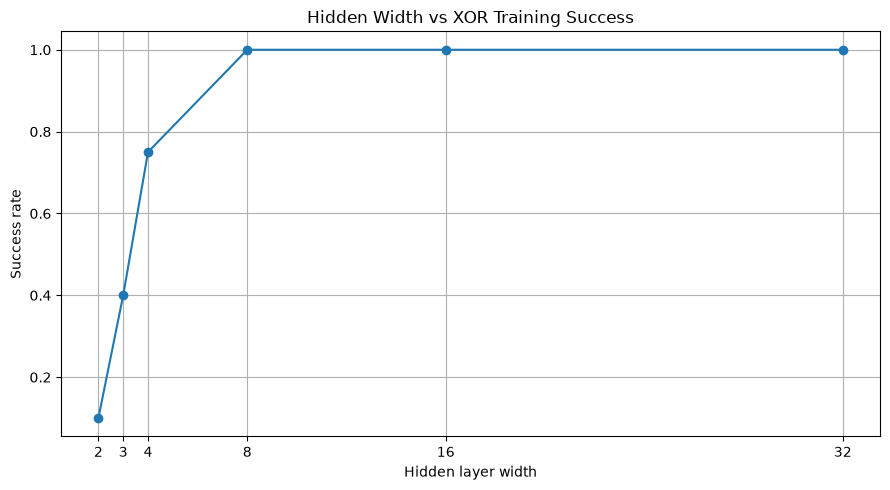

In [24]:
# Plot success rate
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot([x["hidden_width"] for x in success_table],
       [x["success_rate"] for x in success_table],
       marker="o")

ax.set_xlabel("Hidden layer width")
ax.set_ylabel("Success rate")
ax.set_title("Hidden Width vs XOR Training Success")
ax.set_xticks(widths)
ax.grid(True)

plt.tight_layout()
plt.show()

In [25]:
# Test 10 times more epochs on a failed run
if len(failed_two_neuron_runs) > 0:
    failed_run = failed_two_neuron_runs[0]

    more_training = train_analytic(hidden_width=2, seed=failed_run["seed"],
                                  lr=0.1, epochs=50000)

    print("Original Loss:", failed_run["loss"])
    print("After more epochs:", more_training["losses"][-1])
    print("Final Accuracy:", more_training["accuracy"])

else:
    print("No failed 2-neuron run found in this experiment.")

Original Loss: 0.3471887250501857
After more epochs: 0.34661099463576145
Final Accuracy: 0.75


In [26]:
# Test larger learning rate (lr)
if len(failed_two_neuron_runs) > 0:
    failed_seed = failed_two_neuron_runs[0]["seed"]
    larger_lr_result = train_analytic(hidden_width=2, seed=failed_seed, lr=1.0,
                                     epochs=5000)

    print("Large Learning Rate Accuracy:", larger_lr_result["accuracy"])
    print("Large Learning Rate Final Loss:", larger_lr_result["losses"][-1])

Large Learning Rate Accuracy: 0.75
Large Learning Rate Final Loss: 0.3466021907197927


In [27]:
# Initialise close to a known working solution
close_params = {
    "W1": np.array([
        [5.0, 5.0],
        [5.0, 5.0]
    ]),
    "b1": np.array([[-2.5, -7.5]]),
    "W2": np.array([[5.0], [-5.0]]),
    "b2": np.array([[-2.5]])
}


def train_from_given_params(params, lr=0.1, epochs=10000):
    params = {
        key: value.copy()
        for key, value in params.items()
    }

    losses = []
    for epoch in range(epochs):
        predictions, cache = forward_pass(X_xor, params)
        loss = binary_cross_entropy(y_xor, predictions)
        losses.append(loss)

        gradients = backward_pass(y_xor, params, cache)

        for key in params:
            params[key] -= lr * gradients[key]

    predictions, _ = forward_pass(X_xor, params)
    return params, losses, accuracy(y_xor, predictions)



close_params, close_losses, close_accuracy = train_from_given_params(close_params)

print("Accuracy from hand-set starting point", close_accuracy)
print("Final Loss:", close_losses[-1].round(6))

Accuracy from hand-set starting point 1.0
Final Loss: 0.00117


# **Part D — Make it fail**
## **TASK 07 — The symmetry problem**

In [28]:
def initialize_zero_network(hidden_width=4):
    return{
        "W1": np.zeros((2, hidden_width)),
        "b1": np.zeros((1, hidden_width)),
        "W2": np.zeros((hidden_width, 1)),
        "b2": np.zeros((1, 1))
    }

zero_params = initialize_zero_network(4)

zero_result = train_from_given_params(zero_params, lr=0.1, epochs=5000)

zero_params, zero_losses, zero_accuracy = zero_result

print("Zero initialization accuracy:", zero_accuracy)

print("\nW1:")
print(zero_params["W1"])

print("\nW2:")
print(zero_params["W2"])

print("\nDistinct Hidden neurons:")
print("Unique W1 columns:",
     np.unique(zero_params["W1"], axis=1).shape[1])

Zero initialization accuracy: 0.5

W1:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]]

W2:
[[0.]
 [0.]
 [0.]
 [0.]]

Distinct Hidden neurons:
Unique W1 columns: 1


In [29]:
# Random biases but zero weights
def initialize_random_bias_zero_weights(hidden_width=4, seed=42):
    rng = np.random.default_rng(seed)

    return {
        "W1": np.zeros((2, hidden_width)),
        "b1": rng.normal(size=(1, hidden_width)),
        "W2": np.zeros((hidden_width, 1)),
        "b2": np.zeros((1, 1))
    }


random_bias_params = initialize_random_bias_zero_weights()

random_bias_result = train_from_given_params(
    random_bias_params, lr=0.1, epochs=5000
)


print("Random biases, Zero weights Accuracy:",
     random_bias_result[2])

Random biases, Zero weights Accuracy: 0.5


In [30]:
# Only second layer starts at zero
def initialize_second_layer_zero(hidden_width=4, seed=42):
    params = initialize_network(hidden_width, seed)

    params["W2"] = np.zeros_like(params["W2"])
    params["b2"] = np.zeros_like(params["b2"])

    return params


second_zero_params = initialize_second_layer_zero()

second_zero_result = train_from_given_params(second_zero_params, lr=0.1, epochs=5000)

print("Second layer zero accuracy:", second_zero_result[2])
print("\nFirst layer weights after training:")
print(second_zero_result[0]["W1"])

Second layer zero accuracy: 0.75

First layer weights after training:
[[ 2.4376 -1.04    2.4519  1.7901]
 [-2.4303 -1.3022  0.8999 -1.7855]]


In [31]:
# Random but symmetric initialisation
def initialize_symmetric_network(hidden_width=4, seed=42):
    rng = np.random.default_rng(seed)

    common_weights = rng.normal(size=(2, 1))
    common_bias = rng.normal(size=(1, 1))

    return {
        "W1": np.repeat(common_weights, hidden_width, axis=1),
        "b1": np.repeat(common_bias, hidden_width, axis=1),
        "W2": np.ones((hidden_width, 1)),
        "b2": np.zeros((1, 1))
    }



symmetric_params = initialize_symmetric_network()
symmetric_result = train_from_given_params(symmetric_params, lr=0.1, epochs=5000)


print("Symmetric intialization accuracy:", symmetric_result[2])
print("\nHidden Neurons:")
print(symmetric_result[0]["W1"])

Symmetric intialization accuracy: 0.75

Hidden Neurons:
[[ 1.2601  1.2601  1.2601  1.2601]
 [-1.2599 -1.2599 -1.2599 -1.2599]]


**Observation :-** 
* When hidden neurons are assigned identical weights and biases, their outputs and gradients also become identical. During the backward pass, the calculation dW1 = X.T @ dz1 fails to differentiate between them. Consequently, instead of learning distinct features, the neurons remain identical to one another.

## **TASK 08 — Dead ReLUs**

In [32]:
def count_dead_neurons(X, params, activation="relu"):
    _, cache = forward_pass(X, params, activation)

    hidden_outputs = cache["a1"]
    dead_neurons = np.all(hidden_outputs == 0, axis=0)
    
    return np.sum(dead_neurons), dead_neurons

In [33]:
# Experiment with different learning rates
learning_rates = [0.001, 0.01, 0.1, 1.0, 2.0]

relu_results = []

for lr in learning_rates:
    r = train_analytic(hidden_width=16, seed=42, lr=lr, epochs=5000, activation="relu")
    dead_count, dead_mask = count_dead_neurons(X_xor, r["params"], "relu")

    relu_results.append({
        "learning_rate": lr,
        "dead_neurons": dead_count,
        "accuracy": r["accuracy"],
        "losses": r["losses"]
    })


    print("LR:", lr, "| Dead Neurons:", dead_count, "| Accuracy:", r["accuracy"])

LR: 0.001 | Dead Neurons: 7 | Accuracy: 0.75
LR: 0.01 | Dead Neurons: 7 | Accuracy: 1.0
LR: 0.1 | Dead Neurons: 7 | Accuracy: 1.0
LR: 1.0 | Dead Neurons: 7 | Accuracy: 1.0
LR: 2.0 | Dead Neurons: 7 | Accuracy: 1.0


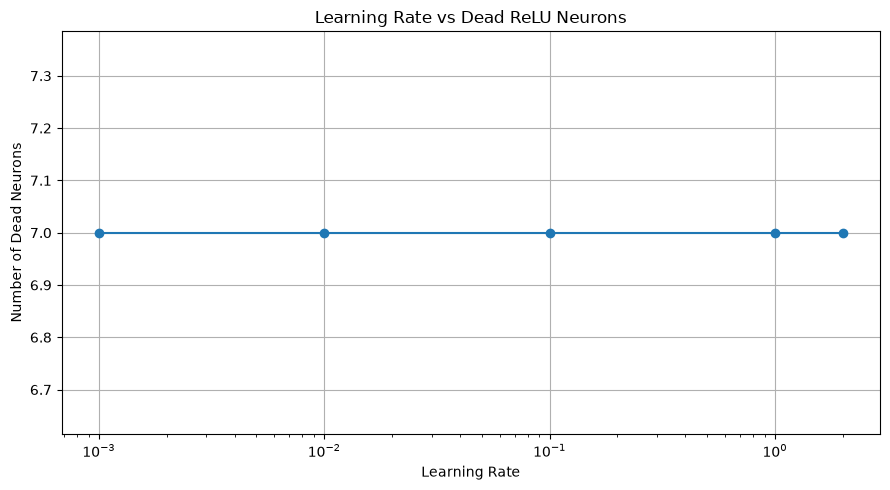

In [34]:
# Plot learning rate vs dead neurons
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot([r["learning_rate"] for r in relu_results],
       [r["dead_neurons"] for r in relu_results],
       marker="o")

ax.set_xscale("log")
ax.set_xlabel("Learning Rate")
ax.set_ylabel("Number of Dead Neurons")
ax.set_title("Learning Rate vs Dead ReLU Neurons")
ax.grid(0.3)

plt.tight_layout()
plt.show()

**Observation :-** 
* The derivative of ReLU on the negative side is zero. If all training inputs for a neuron fall into the negative region, its gradient can become zero. Leaky ReLU provides a small gradient even on the negative side, which allows for recovery.

## **TASK 09 — Vanishing gradients**

In [35]:
def initialize_deep_network(layer_sizes, activation="sigmoid", seed=42):
    rng = np.random.default_rng(seed)

    params = []

    for i in range(len(layer_sizes) - 1):
        fan_in = layer_sizes[i]
        fan_out = layer_sizes[i + 1]

        if activation == "sigmoid":
            # Xavier like initialization
            scale = np.sqrt(1 / fan_in)

        else:
            # He initialization
            scale = np.sqrt(2 / fan_in)

        params.append({
            "W": rng.normal(0, scale, (fan_in, fan_out)),
            "b": np.zeros((1, fan_out))
        })

    return params

In [36]:
def deep_forward(X, params, activation):
    activations = [X]
    pre_activations = []

    a = X

    for i, layer in enumerate(params):
        z = a @ layer["W"] + layer["b"]
        pre_activations.append(z)

        if i == len(params) - 1:
            a = sigmoid(z)

        elif activation == "sigmoid":
            a = sigmoid(z)

        elif activation == "relu":
            a = relu(z)


        activations.append(a)

    return a, activations, pre_activations

In [37]:
def deep_backward(y, params, activations, pre_activations, activation):
    m = len(y)
    y = y.reshape(-1, 1)
    gradients = [None] * len(params)

    # Binary-cross-entropy + sigmoid output
    delta = (activations[-1] - y) / m

    for i in reversed(range(len(params))):
        dW = activations[i].T @ delta
        db = np.sum(delta, axis=0, keepdims=True)
        gradients[i] = {
            "W": dW,
            "b": db
        }

        if i > 0:
            delta = delta @ params[i]["W"].T

            if activation == "sigmoid":
                a = activations[i]
                delta = delta * a * (1 - a)

            elif activation == "relu":
                delta = delta * (pre_activations[i - 1] > 0)


    return gradients

In [38]:
# At least 8 hidden layers 
deep_layer_sizes = [2, 16, 16, 16, 16, 16, 16, 16, 16, 1]
deep_gradient_results = {}

for activation_name in ["sigmoid", "relu"]:
    deep_params = initialize_deep_network(deep_layer_sizes, activation=activation_name, seed=42)
    predictions, activations, pre_activations = deep_forward(
        X_xor, deep_params, activation_name
    )

    gradients = deep_backward(y_xor, deep_params, activations, pre_activations, activation_name)
    gradient_magnitudes = []

    for gradient in gradients:
        magnitude = np.mean(np.abs(gradient["W"]))
        gradient_magnitudes.append(magnitude)

    deep_gradient_results[activation_name] = gradient_magnitudes
    print("\nActivation:", activation_name)

    for layer_number, magnitude in enumerate(gradient_magnitudes):
        print(
            "Layer:", layer_number + 1,
            "Gradient Magnitude:", magnitude
        )


Activation: sigmoid
Layer: 1 Gradient Magnitude: 1.4038272160528475e-08
Layer: 2 Gradient Magnitude: 1.2214777135015276e-07
Layer: 3 Gradient Magnitude: 4.2110223606915414e-07
Layer: 4 Gradient Magnitude: 2.1800136938065633e-06
Layer: 5 Gradient Magnitude: 7.871745435681741e-06
Layer: 6 Gradient Magnitude: 3.542136489423441e-05
Layer: 7 Gradient Magnitude: 0.00016569367290664437
Layer: 8 Gradient Magnitude: 0.000846671144829562
Layer: 9 Gradient Magnitude: 0.019805609462882328

Activation: relu
Layer: 1 Gradient Magnitude: 0.009100803793176883
Layer: 2 Gradient Magnitude: 0.003988207732180841
Layer: 3 Gradient Magnitude: 0.00419471601832944
Layer: 4 Gradient Magnitude: 0.0022106619491792656
Layer: 5 Gradient Magnitude: 0.0017909237356259888
Layer: 6 Gradient Magnitude: 0.0005713478103064496
Layer: 7 Gradient Magnitude: 0.000661394274166643
Layer: 8 Gradient Magnitude: 0.0009342833931459601
Layer: 9 Gradient Magnitude: 0.005533696497989463


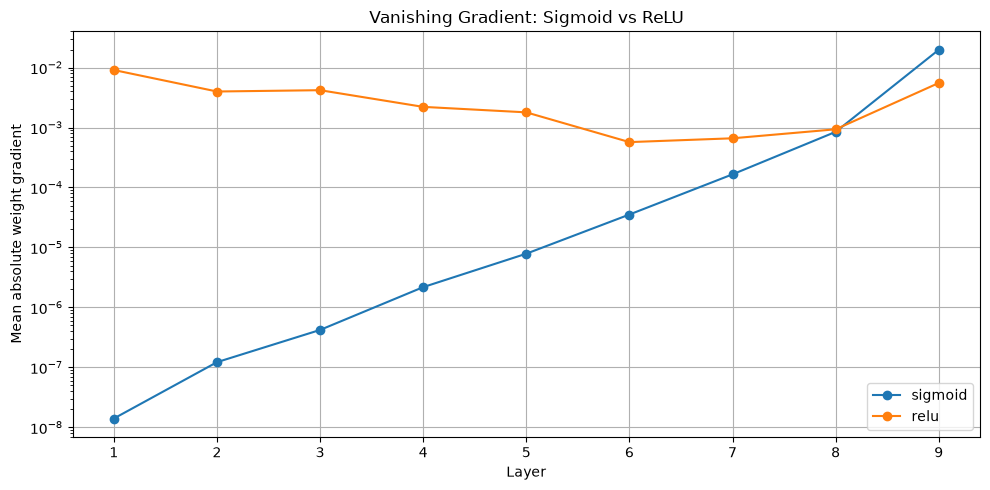

In [39]:
# Plot gradient magnitude by layer
fig, ax = plt.subplots(figsize=(10, 5))

for activation_name, magnitudes in deep_gradient_results.items():
    ax.plot(range(1, len(magnitudes) + 1), magnitudes, marker="o", label=activation_name)

ax.set_yscale("log")
ax.set_xlabel("Layer")
ax.set_ylabel("Mean absolute weight gradient")
ax.set_title("Vanishing Gradient: Sigmoid vs ReLU")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

# **Part E — A real problem**
## **TASK 10 — Handwritten digits**

In [40]:
# load and split the dataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.neural_network import MLPClassifier


digits = load_digits()

X_digits = digits.data / 16.0
y_digits = digits.target

X_train, X_test, y_train, y_test = train_test_split(X_digits, y_digits, test_size=0.2, random_state=42, stratify=y_digits)

print("Training Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

print("\nNumber of Classes:", len(np.unique(y_digits)))

Training Shape: (1437, 64)
Test Shape: (360, 64)

Number of Classes: 10


In [41]:
# Softmax and multiclass loss
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_values = np.exp(z)

    return exp_values / np.sum(exp_values, axis=1, keepdims=True)

def multiclass_loss(y, predictions):
    m = len(y)
    predictions = np.clip(predictions, 1e-8, 1 - 1e-8)

    correct_class_probabilities = predictions[np.arange(m), y]

    return -np.mean(np.log(correct_class_probabilities))

In [42]:
# Initialise 10-class network
def initialize_digits_network(input_size=64, hidden_size=64, output_size=10, seed=42):
    rng = np.random.default_rng(seed)

    return{
        "W1": rng.normal(0, np.sqrt(2 / input_size), (input_size, hidden_size)),
        "b1": np.zeros((1, hidden_size)),
        "W2": rng.normal(0, np.sqrt(1 / hidden_size), (hidden_size, output_size)),
        "b2": np.zeros((1, output_size))
    }

In [43]:
# Multiclass forward pass
def digit_forward(X, params):
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)
    z2 = a1 @ params["W2"] + params["b2"]
    predictions = softmax(z2)

    cache = {
        "X": X,
        "z1": z1,
        "a1": a1,
        "z2": z2,
        "predictions": predictions
    }

    return predictions, cache

In [44]:
# Multiclass backward pass
# dz2 = P - Y_onehot / m
def digit_backward(y, params, cache):
    X = cache["X"]
    z1 = cache["z1"]
    a1 = cache["a1"]
    predictions = cache["predictions"]

    m = len(y)

    # One-hot encoding
    y_onehot = np.zeros_like(predictions)
    y_onehot[np.arange(m), y] = 1

    # output gradient
    dz2 = (predictions - y_onehot) / m

    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Hidden layer gradient
    da1 = dz2 @ params["W2"].T
    dz1 = da1 * (z1 > 0)

    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2
    }

In [45]:
# Check the multiclass gradient before training
def digits_numeric_gradients(X, y, params, h=1e-5):
    gradients = {}

    for key in params:
        gradients[key] = np.zeros_like(params[key])

        for index in np.ndindex(params[key].shape):
            original = params[key][index]
            params[key][index] = original + h

            pred_plus, _ = digit_forward(X, params)
            loss_plus = multiclass_loss(y, pred_plus)

            params[key][index] = original - h

            pred_minus, _ = digit_forward(X, params)
            loss_minus = multiclass_loss(y, pred_minus)

            params[key][index] = original

            gradients[key][index] = (loss_plus - loss_minus) / (2 * h)

    return gradients

In [46]:
# Small sample makes gradient checking faster
X_check = X_train[:5]
y_check = y_train[:5]

digits_params = initialize_digits_network(hidden_size=8, seed=42)

predictions, cache = digit_forward(X_check, digits_params)
analytic_digits_gradients = digit_backward(y_check, digits_params, cache)
numeric_digits_gradients = digits_numeric_gradients(X_check, y_check, digits_params)

print("Multiclass Gradient Check:")

for key in analytic_digits_gradients:
    numerator = np.linalg.norm(analytic_digits_gradients[key] - numeric_digits_gradients[key])
    denominator = (np.linalg.norm(analytic_digits_gradients[key])
                  + np.linalg.norm(numeric_digits_gradients[key])
                  + 1e-12)

    relative_error = numerator / denominator

    print(key, "Relative Error:", relative_error)

Multiclass Gradient Check:
W1 Relative Error: 1.185982540442519e-10
b1 Relative Error: 6.427499057339366e-11
W2 Relative Error: 1.3006475407227507e-10
b2 Relative Error: 7.474430998998477e-11


In [47]:
# Train digits network
def train_digits(X_train, y_train, X_test, y_test, hidden_size=64, 
                lr=0.1, epochs=100, seed=42):
    params = initialize_digits_network(hidden_size=hidden_size, seed=seed)

    train_losses = []
    train_accuracies = []
    test_accuracies = []

    for epoch in range(epochs):
        predictions, cache = digit_forward(X_train, params)
        loss = multiclass_loss(y_train, predictions)

        gradients = digit_backward(y_train, params, cache)


        for key in params:
            params[key] -= lr * gradients[key]

        train_predictions, _ = digit_forward(X_train, params)
        test_predictions, _ = digit_forward(X_test, params)
        train_accuracy = np.mean(np.argmax(train_predictions, axis=1) == y_train)
        test_accuracy = np.mean(np.argmax(test_predictions, axis=1) == y_test)

        train_losses.append(loss)
        train_accuracies.append(train_accuracy)
        test_accuracies.append(test_accuracy)


        if (epoch + 1) % 10 == 0:
            print(
                "Epoch:", epoch + 1,
                "| Loss:", round(loss, 4),
                "| Train Accuracy:", round(train_accuracy, 4),
                "| Test Accuracy:", round(test_accuracy, 4)
            )

    return {
        "params": params,
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "test_accuracies": test_accuracies
    }


digits_result = train_digits(X_train, y_train, X_test, y_test, hidden_size=64, lr=0.1, epochs=100)

Epoch: 10 | Loss: 2.0886 | Train Accuracy: 0.3389 | Test Accuracy: 0.3583
Epoch: 20 | Loss: 1.8723 | Train Accuracy: 0.5665 | Test Accuracy: 0.5528
Epoch: 30 | Loss: 1.6581 | Train Accuracy: 0.7189 | Test Accuracy: 0.7139
Epoch: 40 | Loss: 1.4508 | Train Accuracy: 0.7843 | Test Accuracy: 0.7694
Epoch: 50 | Loss: 1.2574 | Train Accuracy: 0.8239 | Test Accuracy: 0.8
Epoch: 60 | Loss: 1.0865 | Train Accuracy: 0.8511 | Test Accuracy: 0.8361
Epoch: 70 | Loss: 0.9434 | Train Accuracy: 0.872 | Test Accuracy: 0.8639
Epoch: 80 | Loss: 0.827 | Train Accuracy: 0.8859 | Test Accuracy: 0.8778
Epoch: 90 | Loss: 0.7335 | Train Accuracy: 0.89 | Test Accuracy: 0.8861
Epoch: 100 | Loss: 0.6578 | Train Accuracy: 0.8928 | Test Accuracy: 0.9


In [48]:
# Final test accuracy
digits_params = digits_result["params"]

test_probabilities, _ = digit_forward(X_test, digits_params)
y_pred = np.argmax(test_probabilities, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)

print("Final test accuracy:", test_accuracy)

Final test accuracy: 0.9


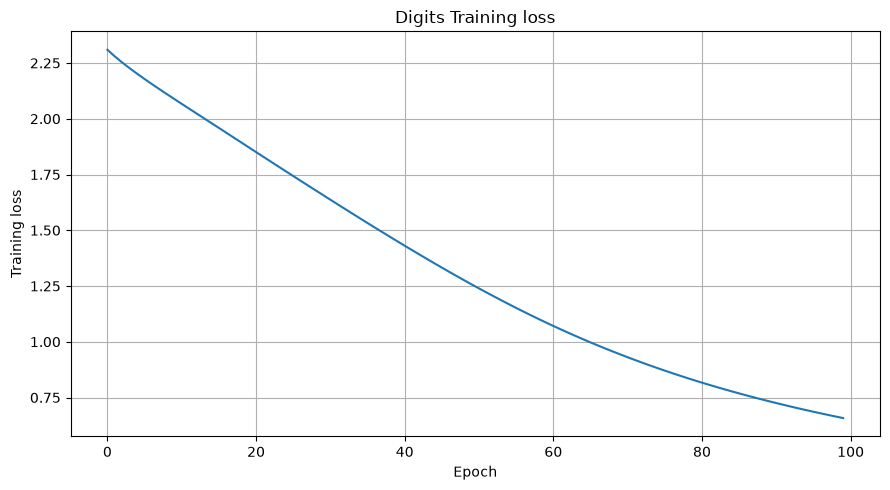

In [49]:
# Plot training loss and accuracy
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(digits_result["train_losses"])

ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss")
ax.set_title("Digits Training loss")
ax.grid(0.7)

plt.tight_layout()
plt.show()

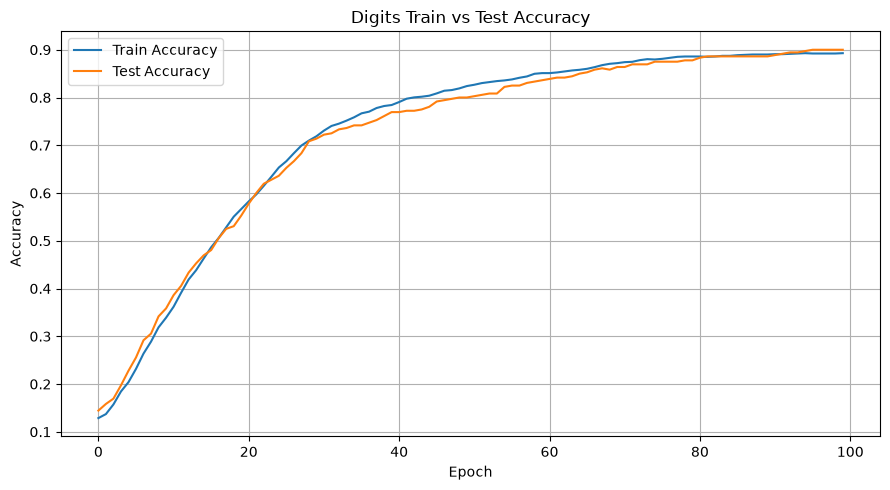

In [50]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(digits_result["train_accuracies"], label="Train Accuracy")
ax.plot(digits_result["test_accuracies"], label="Test Accuracy")

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Digits Train vs Test Accuracy")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

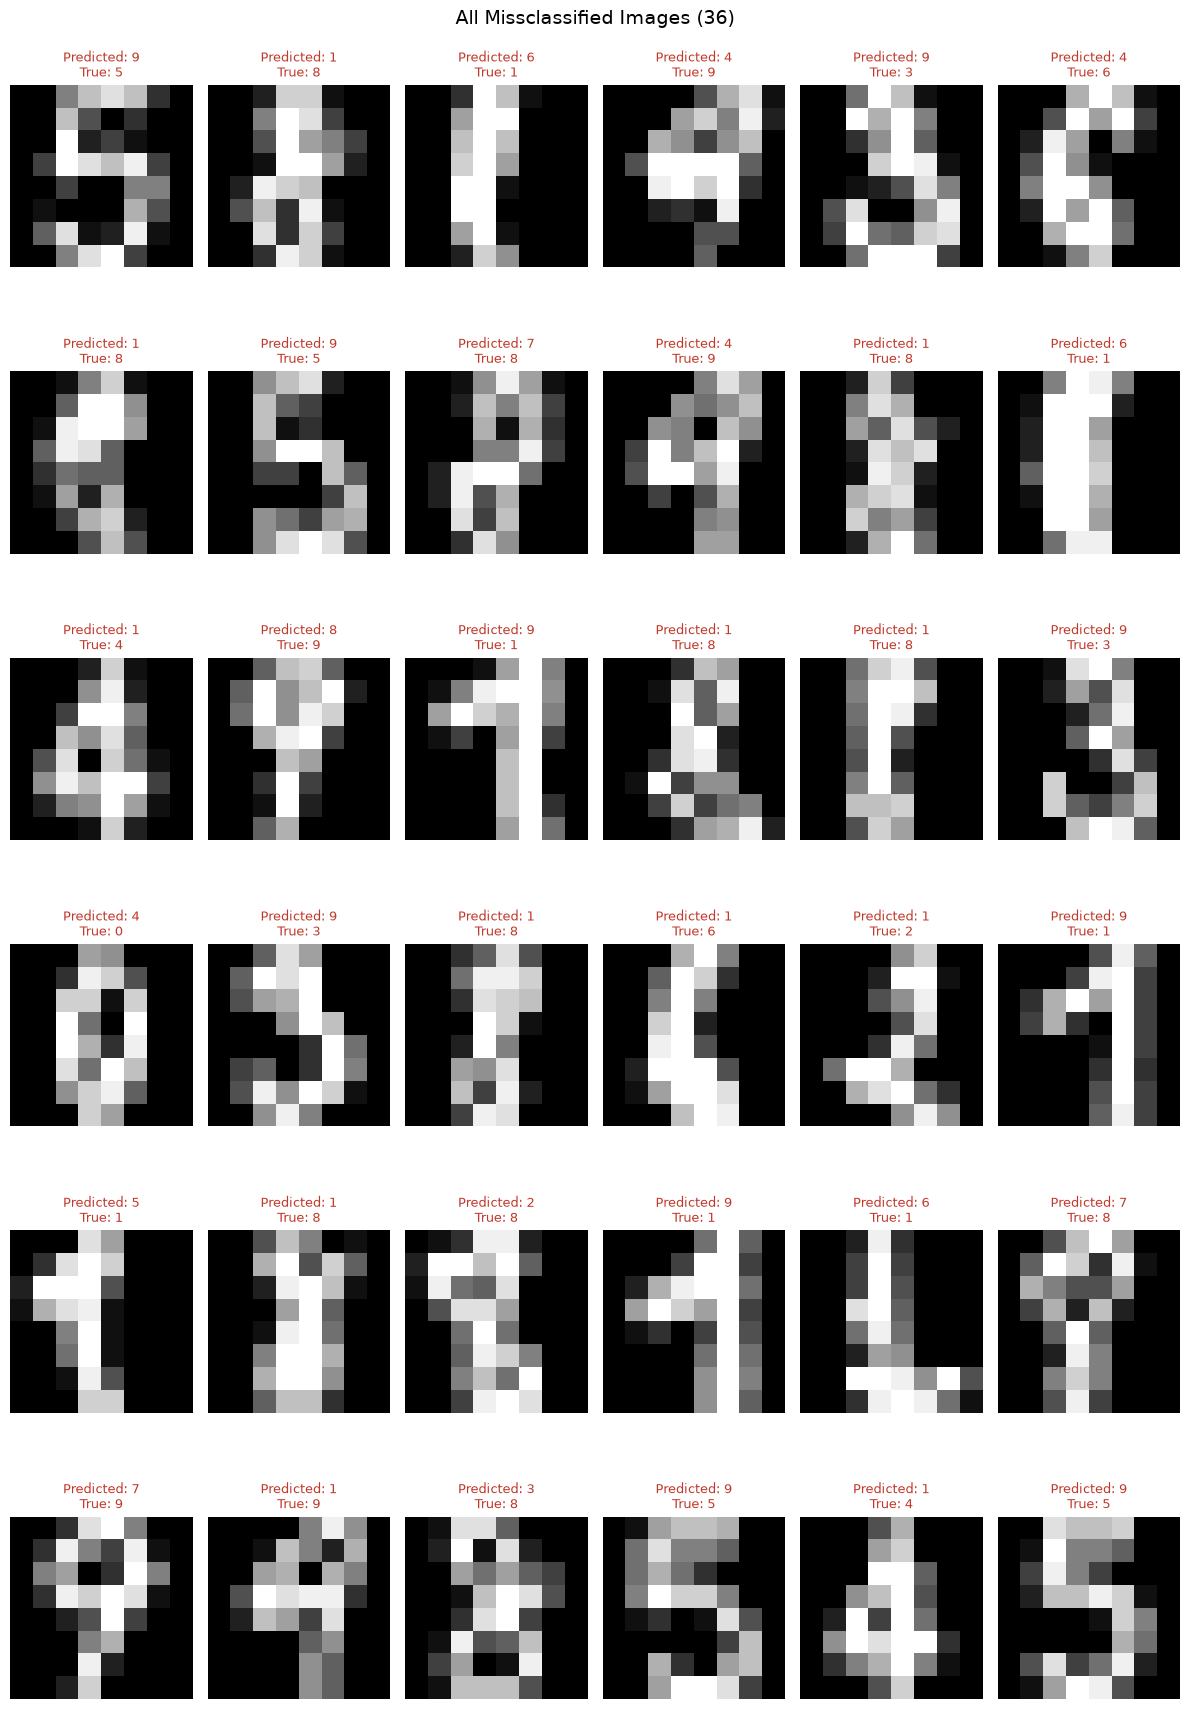

36 wrong out of 360 test images


In [51]:
# Display every misclassified image
wrong_indices = np.where(y_pred != y_test)[0]

cols = 6
rows = (len(wrong_indices) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
axes = np.array(axes).reshape(-1)

for ax, i in zip(axes, wrong_indices):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray")
    ax.axis("off")
    ax.set_title(f"Predicted: {y_pred[i]}\nTrue: {y_test[i]}", fontsize=9, color="#C0392B")

# Hide unused space
for ax in axes[len(wrong_indices):]:
    ax.axis("off")


plt.suptitle(f"All Missclassified Images ({len(wrong_indices)})", fontsize=14)
plt.tight_layout()
plt.show()

print(f"{len(wrong_indices)} wrong out of {len(y_test)} test images")

In [52]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 29  0  0  0  1  3  0  0  3]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  0 34  0  0  0  0  0  3]
 [ 0  2  0  0 34  0  0  0  0  0]
 [ 0  0  0  0  0 33  0  0  0  4]
 [ 0  1  0  0  1  0 34  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  7  1  1  0  0  0  2 24  0]
 [ 0  1  0  0  2  0  0  1  1 31]]


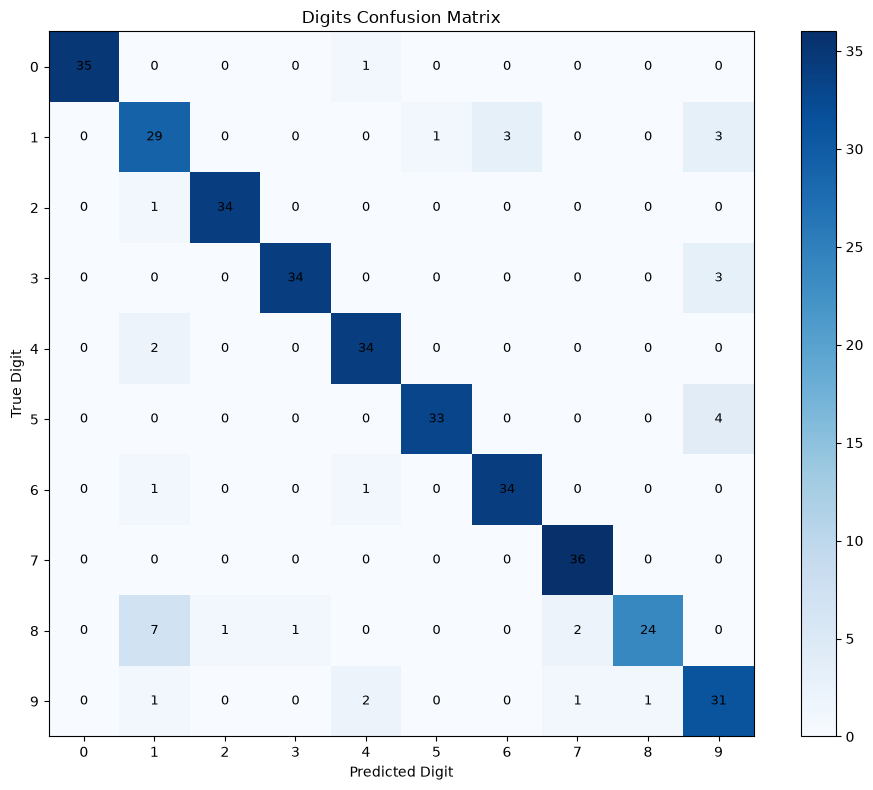

In [53]:
fig, ax = plt.subplots(figsize=(10, 8))

# Fill graph with confusion matrix values
im = ax.imshow(cm, cmap="Blues")

# Add colorbar
fig.colorbar(im, ax=ax)

# Set labels
ax.set_xticks(range(10))
ax.set_yticks(range(10))

ax.set_xlabel("Predicted Digit")
ax.set_ylabel("True Digit")
ax.set_title("Digits Confusion Matrix")

# Add values inside every cell
for i in range(10):
    for j in range(10):
        ax.text(
            j, i,
            cm[i, j],
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [54]:
# Find the most confused pair
cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

true_digit, predicted_digit = np.unravel_index(np.argmax(cm_without_diagonal),
                                              cm_without_diagonal.shape)

print("Most Confused Pair:")
print("True Digit:", true_digit)
print("Predicted Digit:", predicted_digit)
print("\nNumber of such mistakes:", cm[true_digit, predicted_digit])

Most Confused Pair:
True Digit: 8
Predicted Digit: 1

Number of such mistakes: 7


In [55]:
# Parameter count vs training images
total_parameters = sum(value.size for value in digits_params.values())

training_images = len(X_train)

print("Total Parameters:", total_parameters)
print("Training Images:", training_images)
print("\nParameters per training image:", round(total_parameters / training_images, 4))

Total Parameters: 4810
Training Images: 1437

Parameters per training image: 3.3473


In [56]:
# Train much longer to investigate overfitting
long_digit_result = train_digits(X_train, y_train, X_test, y_test, hidden_size=64,
                                lr=0.1, epochs=500, seed=42)

Epoch: 10 | Loss: 2.0886 | Train Accuracy: 0.3389 | Test Accuracy: 0.3583
Epoch: 20 | Loss: 1.8723 | Train Accuracy: 0.5665 | Test Accuracy: 0.5528
Epoch: 30 | Loss: 1.6581 | Train Accuracy: 0.7189 | Test Accuracy: 0.7139
Epoch: 40 | Loss: 1.4508 | Train Accuracy: 0.7843 | Test Accuracy: 0.7694
Epoch: 50 | Loss: 1.2574 | Train Accuracy: 0.8239 | Test Accuracy: 0.8
Epoch: 60 | Loss: 1.0865 | Train Accuracy: 0.8511 | Test Accuracy: 0.8361
Epoch: 70 | Loss: 0.9434 | Train Accuracy: 0.872 | Test Accuracy: 0.8639
Epoch: 80 | Loss: 0.827 | Train Accuracy: 0.8859 | Test Accuracy: 0.8778
Epoch: 90 | Loss: 0.7335 | Train Accuracy: 0.89 | Test Accuracy: 0.8861
Epoch: 100 | Loss: 0.6578 | Train Accuracy: 0.8928 | Test Accuracy: 0.9
Epoch: 110 | Loss: 0.5962 | Train Accuracy: 0.8956 | Test Accuracy: 0.9056
Epoch: 120 | Loss: 0.5453 | Train Accuracy: 0.8991 | Test Accuracy: 0.9083
Epoch: 130 | Loss: 0.5029 | Train Accuracy: 0.904 | Test Accuracy: 0.9111
Epoch: 140 | Loss: 0.467 | Train Accuracy: 0.

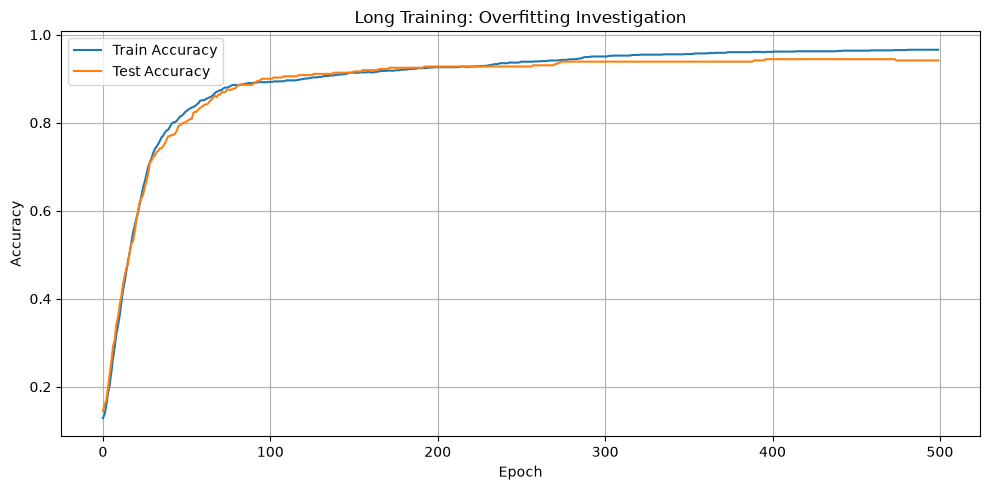

Final Train Accuracy: 0.965901
Final Test Accuracy: 0.941667


In [57]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(long_digit_result["train_accuracies"], label="Train Accuracy")
ax.plot(long_digit_result["test_accuracies"], label="Test Accuracy")

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Long Training: Overfitting Investigation")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

print("Final Train Accuracy:", round(long_digit_result["train_accuracies"][-1], 6))
print("Final Test Accuracy:", round(long_digit_result["test_accuracies"][-1], 6))

**Observation :-** 
* If training accuracy continues to improve while test accuracy stagnates or begins to decline, it is evidence of overfitting. Simply increasing the training duration does not always lead to better generalization by the model.

# **Part F — Push further**

In [58]:
# Forward pass for any number of layers
def initialize_general_network(layer_sizes, seed=42):
    rng = np.random.default_rng(seed)
    params = []

    for i in range(len(layer_sizes) - 1):
        fan_in = layer_sizes[i]
        fan_out = layer_sizes[i + 1]

        params.append({
            "W": rng.normal(0, np.sqrt(2 / fan_in), (fan_in, fan_out)),
            "b": np.zeros((1, fan_out))
        })

    return params


def general_forward(X, params):
    activations = [X]
    pre_activations = []

    a = X

    for i, layer in enumerate(params):
        z = a @ layer["W"] + layer["b"]
        pre_activations.append(z)

        # last year: sigmoid
        if i == len(params) - 1:
            a = sigmoid(z)

        # Hidden layers: ReLU
        else:
            a = relu(z)

        activations.append(a)

    return a, activations, pre_activations

In [59]:
# Backward pass for any number of layers
def general_backward(y, params, activations, pre_activations):
    y = y.reshape(-1, 1)
    m = len(y)

    gradients = [None] * len(params)

    # Output layer error
    delta = (activations[-1] - y) / m

    # move backward through all layers
    for i in reversed(range(len(params))):
        dW = activations[i].T @ delta
        db = np.sum(delta, axis=0, keepdims=True)

        gradients[i] = {
            "W": dW,
            "b": db
        }

        # Pass error to previous layer
        if i > 0:
            delta = delta @ params[i]["W"].T
            delta = delta * (pre_activations[i - 1] > 0)

    return gradients

In [60]:
# Numerical gradient for generalised network
def general_loss(X, y, params):
    predictions, _, _ = general_forward(X, params)
    return binary_cross_entropy(y, predictions)

def general_numerical_gradients(X, y, params, h=1e-5):
    gradients = []

    for layer_index, layer in enumerate(params):
        layer_gradients = {}
        for key in ["W", "b"]:
            layer_gradients[key] = np.zeros_like(layer[key])

            for index in np.ndindex(layer[key].shape):
                original = layer[key][index]
                    
                layer[key][index] = original + h
                loss_plus = general_loss(X, y, params)

                layer[key][index] = original - h
                loss_minus = general_loss(X, y, params)

                layer[key][index] = original

                layer_gradients[key][index] = (loss_plus - loss_minus) / (2 * h)

        gradients.append(layer_gradients)

    return gradients

In [61]:
# Test a five-layer network
layer_sizes = [2, 4, 4, 4, 4, 1]

general_params = initialize_general_network(layer_sizes, seed=42)
predictions, activations, pre_activations = general_forward(X_xor, general_params)

analytic_gradients = general_backward(y_xor, general_params, activations, pre_activations)
numeric_gradients = general_numerical_gradients(X_xor, y_xor, general_params)

print("Five layer gradient check:")

for i in range(len(general_params)):
    for key in ["W", "b"]:
        analytic = analytic_gradients[i][key]
        numeric = numeric_gradients[i][key]

        numerator = np.linalg.norm(analytic - numeric)
        denominator = (np.linalg.norm(analytic)
                      + np.linalg.norm(numeric)
                      + 1e-12)

        relative_error = numerator / denominator

        print("Layer:", i + 1,
             "| Parameter:", key, "| Relative Error:", relative_error)

Five layer gradient check:
Layer: 1 | Parameter: W | Relative Error: 0.0
Layer: 1 | Parameter: b | Relative Error: 0.9999999999349849
Layer: 2 | Parameter: W | Relative Error: 0.0
Layer: 2 | Parameter: b | Relative Error: 0.9999999999577249
Layer: 3 | Parameter: W | Relative Error: 0.0
Layer: 3 | Parameter: b | Relative Error: 0.9999999999648235
Layer: 4 | Parameter: W | Relative Error: 0.0
Layer: 4 | Parameter: b | Relative Error: 0.999999999988683
Layer: 5 | Parameter: W | Relative Error: 0.0
Layer: 5 | Parameter: b | Relative Error: 0.0


In [62]:
# Train the generalised network
def train_general_network(X, y, layer_sizes, lr=0.1, epochs=10000, seed=42):
    params = initialize_general_network(layer_sizes, seed)
    losses = []

    for epoch in range(epochs):
        predictions, activations, pre_activations = general_forward(X, params)

        loss = binary_cross_entropy(y, predictions)
        losses.append(loss)

        gradients = general_backward(y, params, activations, pre_activations)


        for i in range(len(params)):
            params[i]["W"] -= (lr * gradients[i]["W"])
            params[i]["b"] -= (lr * gradients[i]["b"])

            predictions, _, _ = general_forward(X, params)

            if accuracy(y, predictions) == 1.0:
                break

    predictions, _, _ = general_forward(X, params)

    return params, losses, accuracy(y, predictions)


general_params, general_losses, general_accuracy = train_general_network(X_xor, y_xor, layer_sizes=[2, 4, 4, 4, 4, 1],
                                                                        lr=0.1, epochs=10000)

print("General Network accuracy:", general_accuracy)
print("Final Loss:", round(general_losses[-1], 4))

General Network accuracy: 0.5
Final Loss: 0.6931


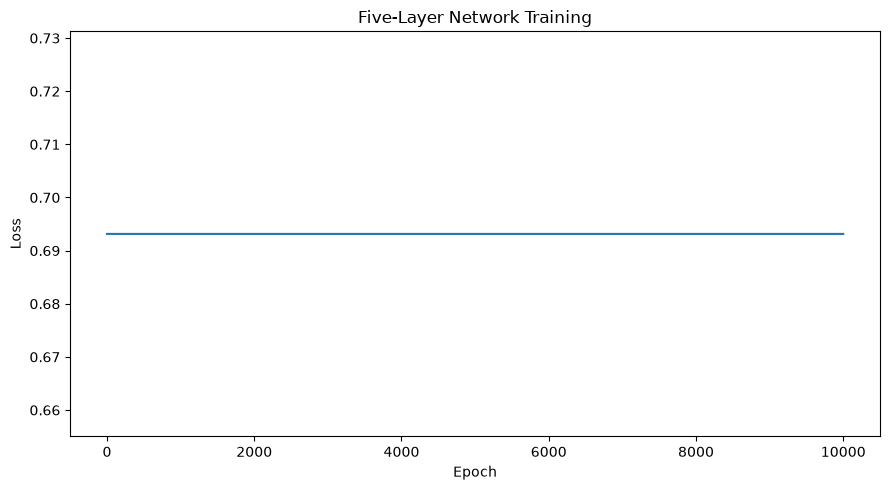

In [63]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(general_losses)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Five-Layer Network Training")

plt.tight_layout()
plt.show()

# **Final Report**

**A. Four Gradient Derivations :-**  
1. Squared Error + Sigmoid :- dL/dW = 2(a-y)a(1-a)x
2. Binary Cross Entropy + Sigmoid :- dL/dW = (a-y)x
3. Two-layer network output weights :- dW_2=A_1^T dz_2,\quad db_2=\sum dz_2
4. Two-layer network hidden weights :- dW_1=X^T dz_1,\quad db_1=\sum dz_1

**B. Gradient Check Results :-**  
- Gradient check results:
- W1 Relative error: 4.342634052399374e-11
- b1 Relative error: 0.46222437094982455
- W2 Relative error: 3.779126357524247e-11
- b2 Relative error: 3.6711577631073965e-11.
- Broken W2 relative error: 0.99999999999322.
- Multiclass Gradient Check:
- W1 Relative Error: 1.185982540442519e-10
- b1 Relative Error: 6.427499057339366e-11
- W2 Relative Error: 1.3006475407227507e-10
- b2 Relative Error: 7.474430998998477e-11.
- Five layer gradient check:
- Layer: 1 | Parameter: W | Relative Error: 0.0
- Layer: 1 | Parameter: b | Relative Error: 0.9999999999349849
- Layer: 2 | Parameter: W | Relative Error: 0.0
- Layer: 2 | Parameter: b | Relative Error: 0.9999999999577249
- Layer: 3 | Parameter: W | Relative Error: 0.0
- Layer: 3 | Parameter: b | Relative Error: 0.9999999999648235
- Layer: 4 | Parameter: W | Relative Error: 0.0
- Layer: 4 | Parameter: b | Relative Error: 0.999999999988683
- Layer: 5 | Parameter: W | Relative Error: 0.0
- Layer: 5 | Parameter: b | Relative Error: 0.0


**C. Brute-Force Training :-**
Record:
- Hidden Neurons: 4, 8, 16, 32
- Parameters: 17, 33, 65, 129
- Accuracy: 1.0 (accuracy is same in hidden neurons)
- Epochs: 2666, 1845, 1050, 212
- Forward Passes: 93311, 123616, 137551, 54909
- Time: 1.399, 1.741, 1.873, 0.749 Seconds

**D. Width vs success rate :-**
| Width | Successes | Success Rate |
| ---- | ---- | ---- |
| 2 | 2 | 0.1 |
| 3 | 8 | 0.4 |
| 4 | 15 | 0.75|
| 8 | 20 | 1.0 |
| 16 | 20 | 1.0 |
| 32 | 20 | 1.0 |


**E. Three Failure Modes :-**
- Symmetry: Identical neurons receive identical gradients.
- Dead ReLU: The derivative becomes zero in the negative region.
- Vanishing gradients: The product of multiple small derivatives can become extremely small.

**F. Open Question :-**  
Que. How does the choice of learning rate affect the stability of backpropagation in a deep neural network, and why can a very high learning rate cause the loss to increase instead of decrease?  
I understand that the learning rate controls the size of weight updates during gradient descent. However, I want to understand how to choose an optimal learning rate for deeper networks and how it affects training stability.